# 02 · Baseline stage 2: portfolios from the MSE predictions

Reproduces the MSE (benchmark) side of the paper's portfolio tables:

* **Table 2:** equal-weighted decile portfolios sorted on predicted returns, rebalanced daily. H-L is (H - L) / 2,
  which is the convention the paper's numbers imply. **Table A.4:** the same, value weighted.
* **Table A.3:** the long-only top decile: turnover, largest one-day loss and maximum drawdown.
* **Table 3:** transaction costs of 0 to 40 bps. *MSE-Top* holds the raw top decile and pays the costs. *MSE-Opt* solves
  the paper's turnover-penalized problem (eq. 19) each day.

Conventions: returns are excess of the market and annualized with 252 days. SR = Avg / SD. Drawdowns use cumulative
sums of daily returns, and Length is calendar days from peak to trough inclusive, as in the paper. Turnover is one-sided,
0.5·‖w_t − w_{t−1}‖₁, so the daily cost is γ × turnover. t-statistics are Newey-West with ⌊T^¼⌋ lags.

In [1]:
from pathlib import Path

import json

import matplotlib.pyplot as plt
import pandas as pd

from mlm import metrics
from mlm.linear import GRIDS as LINEAR_GRIDS
from mlm.metrics import drawdown, nw_tstat, oos_r2, perf
from mlm.models import MODELS as ALL_MODELS
from mlm.portfolio import decile_returns, top_portfolio
from mlm.train import load_predictions

DATA_SOURCE = "cn"
SOURCES = {
    "cn": dict(panel="D:/ML_Markowitz_data/panel_cn", preds="D:/ML_Markowitz_data/preds/cn"),
    "synthetic": dict(panel="data_synth/panel", preds="preds/synthetic"),
}
PANEL_DIR, PRED_DIR = (Path(SOURCES[DATA_SOURCE][k]) for k in ("panel", "preds"))
metrics.ANN = json.loads((PANEL_DIR / "meta.json").read_text()).get("ann", 252)
print("annualization:", round(metrics.ANN, 1), "days")
RES_DIR, FIG_DIR = Path("results") / DATA_SOURCE, Path("figures") / DATA_SOURCE
RES_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

MODELS = [m for m in ALL_MODELS + list(LINEAR_GRIDS) if (PRED_DIR / m).exists()]
TC_MODEL = "NN3" if "NN3" in MODELS else MODELS[-1]
TCRS = [0, 10, 20, 30, 40]

preds = {m: load_predictions(PRED_DIR, m) for m in MODELS}
pd.DataFrame({m: {"first": p.date.min().date(), "last": p.date.max().date(), "days": p.date.nunique(),
                  "stocks/day": round(len(p) / p.date.nunique())} for m, p in preds.items()}).T

annualization: 242.9 days


,first,last,days,stocks/day
Linear,2014-01-02,2023-12-29,2434,3348
NN1,2014-01-02,2023-12-29,2434,3348
NN2,2014-01-02,2023-12-29,2434,3348
NN3,2014-01-02,2023-12-29,2434,3348
NN4,2014-01-02,2023-12-29,2434,3348
NN5,2014-01-02,2023-12-29,2434,3348
OLS,2014-01-02,2023-12-29,2434,3348
Ridge,2014-01-02,2023-12-29,2434,3348
Ridge-rank,2014-01-02,2023-12-29,2434,3348
PCR,2014-01-02,2023-12-29,2434,3348


## Out-of-sample R² (%, pooled against a zero forecast)

In [2]:
r2 = pd.Series({m: 100 * oos_r2(p["pred"], p["target"]) for m, p in preds.items()}, name="OOS R2 %")
r2.to_csv(RES_DIR / "oos_r2.csv")
r2.round(3)

Linear        0.091
NN1           0.104
NN2           0.121
NN3           0.135
NN4           0.167
NN5           0.138
OLS           0.080
Ridge         0.071
Ridge-rank    0.090
PCR           0.053
PLS           0.080
LDA           0.084
LDA-top       0.046
Name: OOS R2 %, dtype: float64

## Table 2 analogue: equal-weighted decile portfolios (MSE)

In [3]:
def decile_table(weight):
    return pd.concat({m: decile_returns(p, weight).apply(perf).T for m, p in preds.items()}, axis=1)

t2 = decile_table("ew")
t2.to_csv(RES_DIR / "table2_mse_deciles_ew.csv")
t2.round(2)

Linear                 NN1                 NN2                 NN3  \
         Avg %   SD %    SR  Avg %   SD %    SR  Avg %   SD %    SR  Avg %   
High(H)  31.10  22.81  1.36  31.75  23.45  1.35  29.62  23.50  1.26  28.95   
2        21.76  21.88  0.99  22.08  22.04  1.00  22.38  22.05  1.01  22.24   
3        17.57  21.39  0.82  17.57  21.31  0.82  18.37  21.34  0.86  17.66   
4        14.03  21.02  0.67  13.47  20.76  0.65  14.35  20.76  0.69  14.06   
5         9.83  20.76  0.47  10.26  20.50  0.50   9.31  20.39  0.46   9.39   
6         6.05  20.61  0.29   6.25  20.20  0.31   7.13  19.97  0.36   7.38   
7        -0.04  20.41 -0.00   2.88  20.13  0.14   1.46  19.88  0.07   1.81   
8        -6.40  20.34 -0.31  -5.35  20.07 -0.27  -3.10  20.04 -0.15  -3.29   
9       -16.41  20.67 -0.79 -15.47  20.57 -0.75 -16.64  20.77 -0.80 -16.99   
Low(L)  -53.42  22.17 -2.41 -59.37  22.82 -2.60 -58.79  23.31 -2.52 -57.13   
H-L      42.26   7.57  5.58  45.56   6.89  6.61  44.21   6.80  6.51  43.04   
H-L raw  84.52  15.15  5.58  91.11  13.78  6.61  88.41  13.59  6.51  86.08   

         ...   PCR    PLS                 LDA              LDA-top         \
         ...    SR  Avg %   SD %    SR  Avg %   SD %    SR   Avg %   SD %   
High(H)  ...  1.09  28.68  22.39  1.28  27.41  22.78  1.20   12.97  19.96   
2        ...  0.88  20.21  21.69  0.93  20.28  21.95  0.92   15.31  20.05   
3        ...  0.71  17.14  21.36  0.80  17.31  21.52  0.80   14.80  20.44   
4        ...  0.58  12.65  21.04  0.60  12.87  21.07  0.61   13.24  20.73   
5        ...  0.43   9.03  20.79  0.43   8.97  20.84  0.43   10.62  20.97   
6        ...  0.31   5.69  20.61  0.28   6.80  20.63  0.33    8.26  21.35   
7        ...  0.10   1.16  20.68  0.06   2.21  20.40  0.11    2.34  21.53   
8        ... -0.17  -4.93  20.48 -0.24  -4.39  20.52 -0.21   -1.27  22.02   
9        ... -0.70 -16.17  20.87 -0.77 -14.10  20.70 -0.68  -10.65  22.64   
Low(L)   ... -2.05 -49.36  22.87 -2.16 -53.29  22.77 -2.34  -41.50  25.03   
H-L      ...  4.42  39.02   7.90  4.94  40.35   8.36  4.83   27.24   9.22   
H-L raw  ...  4.42  78.04  15.80  4.94  80.70  16.72  4.83   54.48  18.45   

               
           SR  
High(H)  0.65  
2        0.76  
3        0.72  
4        0.64  
5        0.51  
6        0.39  
7        0.11  
8       -0.06  
9       -0.47  
Low(L)  -1.66  
H-L      2.95  
H-L raw  2.95  

[12 rows x 39 columns]

## Table A.4 analogue: value-weighted decile portfolios (MSE)

In [4]:
ta4 = decile_table("vw")
ta4.to_csv(RES_DIR / "tableA4_mse_deciles_vw.csv")
ta4.round(2)

Linear                 NN1                 NN2                 NN3  \
         Avg %   SD %    SR  Avg %   SD %    SR  Avg %   SD %    SR  Avg %   
High(H)  23.05  22.78  1.01  19.00  23.59  0.81  17.33  23.29  0.74  17.39   
2        12.29  21.43  0.57  12.55  21.78  0.58  12.12  21.92  0.55   7.53   
3        10.30  20.62  0.50   7.98  20.81  0.38  10.40  21.00  0.50   6.48   
4         4.55  20.31  0.22   8.48  20.16  0.42   8.36  20.25  0.41   3.66   
5         3.93  20.05  0.20   7.86  20.00  0.39   4.82  19.89  0.24   3.99   
6         3.08  20.19  0.15   3.18  19.70  0.16   1.70  19.91  0.09   3.26   
7        -5.57  20.06 -0.28   0.50  19.88  0.03  -0.89  19.55 -0.05   1.24   
8        -6.66  20.19 -0.33  -4.34  20.29 -0.21  -5.53  20.06 -0.28  -2.72   
9       -13.02  20.59 -0.63 -15.54  20.61 -0.75 -17.40  20.67 -0.84 -17.72   
Low(L)  -37.51  22.04 -1.70 -51.10  22.70 -2.25 -50.62  23.21 -2.18 -51.18   
H-L      30.28  10.83  2.80  35.05  10.55  3.32  33.98  10.02  3.39  34.28   
H-L raw  60.56  21.66  2.80  70.09  21.10  3.32  67.96  20.03  3.39  68.56   

         ...   PCR    PLS                 LDA              LDA-top         \
         ...    SR  Avg %   SD %    SR  Avg %   SD %    SR   Avg %   SD %   
High(H)  ...  0.66  17.62  22.01  0.80  18.84  22.51  0.84    4.51  20.04   
2        ...  0.43  12.53  21.20  0.59  11.32  21.63  0.52    3.98  20.77   
3        ...  0.24   8.51  20.66  0.41   8.14  20.73  0.39    4.26  20.39   
4        ...  0.27   4.28  20.43  0.21   4.14  20.45  0.20    5.24  20.46   
5        ...  0.12  -0.17  19.98 -0.01   2.37  20.00  0.12    1.23  20.43   
6        ...  0.01   1.02  20.26  0.05   2.14  19.77  0.11   -2.01  20.39   
7        ...  0.00  -2.13  20.03 -0.11   0.04  20.13  0.00   -3.47  20.49   
8        ... -0.28  -3.78  20.31 -0.19  -5.01  20.59 -0.24   -4.34  21.54   
9        ... -0.59 -15.95  20.95 -0.76 -11.44  20.95 -0.55  -12.98  22.07   
Low(L)   ... -1.52 -35.49  23.13 -1.53 -39.44  23.24 -1.70  -32.00  25.23   
H-L      ...  2.21  26.55  11.02  2.41  29.14  11.57  2.52   18.25  11.61   
H-L raw  ...  2.21  53.11  22.04  2.41  58.28  23.13  2.52   36.51  23.22   

               
           SR  
High(H)  0.23  
2        0.19  
3        0.21  
4        0.26  
5        0.06  
6       -0.10  
7       -0.17  
8       -0.20  
9       -0.59  
Low(L)  -1.27  
H-L      1.57  
H-L raw  1.57  

[12 rows x 39 columns]

## Table A.3 analogue: long-only top decile (MSE, no costs)

In [5]:
ta3 = pd.DataFrame({m: pd.concat([pd.Series({"Turnover %": tp["to_p"].mean() * 100}), perf(tp["gross"]),
                                  drawdown(tp["gross"])])
                    for m, p in preds.items() for tp in [top_portfolio(p)]}).T
ta3.to_csv(RES_DIR / "tableA3_mse_top.csv")
ta3

,Turnover %,Avg %,SD %,SR,MDD-1D %,MDD %,MDD Begin,MDD End,Length
Linear,32.468196,31.116924,22.811343,1.364099,10.124945,29.882854,2015-06-23,2015-07-06,14
NN1,28.219007,31.763698,23.444861,1.354826,10.23382,30.926848,2015-06-16,2015-07-06,21
NN2,29.621722,29.643883,23.498129,1.261542,10.369986,31.262405,2015-05-26,2015-07-06,42
NN3,28.303057,28.980162,23.526692,1.231799,10.001205,31.566627,2015-05-26,2015-07-06,42
NN4,29.417306,30.48886,23.570564,1.293514,10.156008,30.427734,2015-06-23,2015-07-06,14
NN5,27.041963,28.615617,23.513839,1.216969,10.117051,32.526849,2015-05-26,2015-07-06,42
OLS,32.886459,31.06802,22.963941,1.352905,9.920784,29.963017,2015-06-23,2015-07-06,14
Ridge,30.966139,27.843316,22.617669,1.231043,9.957621,29.728196,2015-06-23,2015-07-06,14
Ridge-rank,38.762119,26.751103,22.307032,1.199223,9.676305,29.814744,2015-06-23,2015-07-06,14
PCR,32.760404,24.601925,22.606724,1.088257,9.841855,29.031825,2015-06-23,2015-07-06,14


## Table 3 analogue: MSE-Top and MSE-Opt under transaction costs

In [6]:
p = preds[TC_MODEL]
rows, daily = [], {}
for tcr in TCRS:
    top, opt = top_portfolio(p, tcr / 1e4), top_portfolio(p, tcr / 1e4, optimize=True)
    daily[tcr] = top["net"], opt["net"]
    for method, d in [("MSE-Top", top), ("MSE-Opt", opt)]:
        rows.append(pd.concat([
            pd.Series({"TCR": tcr, "Method": method}),
            perf(d["net"]).set_axis(["Ann Ret %", "Ann SD %", "Ann SR"]),
            pd.Series({"TO-P %": d["to_p"].mean() * 100, "TO-S %": d["to_s"].mean() * 100}),
            drawdown(d["net"]),
        ]))
    diff = opt["net"] - top["net"]
    rows[-1]["t-stat Opt vs Top"] = nw_tstat(diff) if diff.abs().max() > 1e-10 else 0.0
t3 = pd.DataFrame(rows).set_index(["TCR", "Method"])
t3.to_csv(RES_DIR / f"table3_mse_tc_{TC_MODEL}.csv")
t3

Ann Ret %   Ann SD %    Ann SR     TO-P %     TO-S %   MDD-1D %  \
TCR Method                                                                     
0   MSE-Top  28.980162  23.526692  1.231799  28.303057  28.303057  10.001205   
    MSE-Opt  28.980162  23.526692  1.231799  28.303057  28.303057  10.001205   
10  MSE-Top  22.104541  23.521211  0.939771  28.303057  28.303057  10.026365   
    MSE-Opt  24.853273  23.403707  1.061937  10.913739  28.303057   9.937523   
20  MSE-Top  15.228920  23.516649  0.647580  28.303057  28.303057  10.051525   
    MSE-Opt  22.062933  23.145887  0.953212   5.919162  28.303057   9.937209   
30  MSE-Top   8.353299  23.513008  0.355263  28.303057  28.303057  10.076684   
    MSE-Opt  18.937475  22.858935  0.828450   3.572978  28.303057  10.101204   
40  MSE-Top   1.477678  23.510287  0.062852  28.303057  28.303057  10.101844   
    MSE-Opt  16.439249  22.640242  0.726107   2.280333  28.303057  10.019974   

                 MDD %   MDD Begin     MDD End  Length  t-stat Opt vs Top  
TCR Method                                                                 
0   MSE-Top  31.566627  2015-05-26  2015-07-06      42                NaN  
    MSE-Opt  31.566627  2015-05-26  2015-07-06      42           0.000000  
10  MSE-Top  32.837737  2016-11-21  2018-02-05     442                NaN  
    MSE-Opt  31.444437  2015-05-26  2015-07-06      42           5.101209  
20  MSE-Top  41.328511  2016-11-21  2018-02-05     442                NaN  
    MSE-Opt  32.271596  2016-11-21  2018-02-05     442           7.150409  
30  MSE-Top  49.819286  2016-11-21  2018-02-05     442                NaN  
    MSE-Opt  34.920448  2016-11-21  2018-02-05     442           8.356086  
40  MSE-Top  76.424917  2016-11-21  2021-02-05    1538                NaN  
    MSE-Opt  35.809156  2016-11-21  2018-02-05     442          10.230843

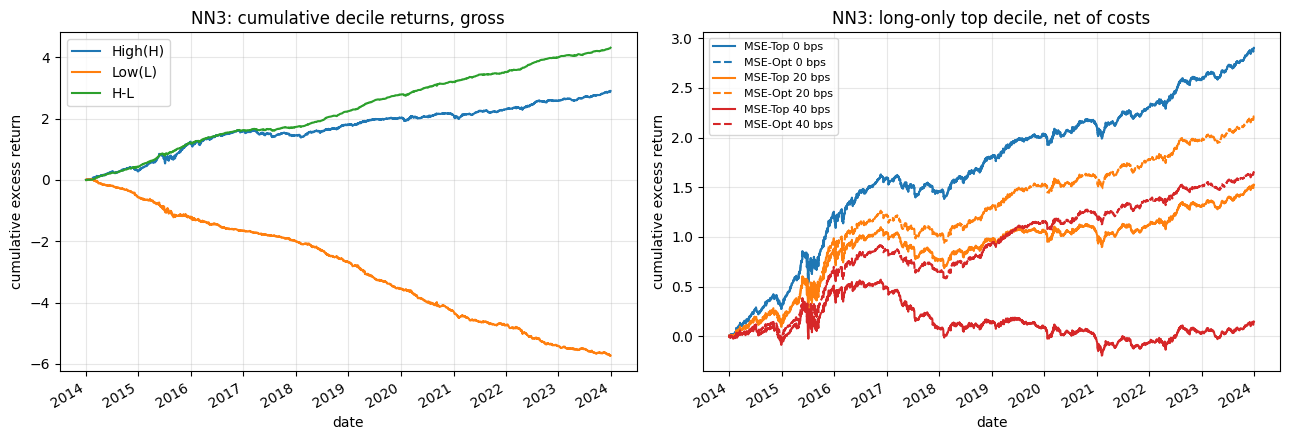

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
dec = decile_returns(p)
dec[["High(H)", "Low(L)", "H-L"]].cumsum().plot(ax=axes[0])
axes[0].set_title(f"{TC_MODEL}: cumulative decile returns, gross")
for tcr, color in zip([0, 20, 40], ["C0", "C1", "C3"]):
    top, opt = daily[tcr]
    top.cumsum().plot(ax=axes[1], color=color, label=f"MSE-Top {tcr} bps")
    opt.cumsum().plot(ax=axes[1], color=color, ls="--", label=f"MSE-Opt {tcr} bps")
axes[1].set_title(f"{TC_MODEL}: long-only top decile, net of costs")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_ylabel("cumulative excess return")
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "baseline_cumulative.png", dpi=150)

## Reading against the paper

These are the benchmark numbers the E2E model will be compared with. On the paper's A-share data, the MSE results are:

* NN3 top decile: Avg 40.0%, SD 20.6%, SR 1.94, turnover 60.6%.
* NN3 H-L: Avg 53.1%, SR 8.88. Most of the H-L return comes from the short (Low) leg.
* MSE-Top falls below zero at 30 bps. MSE-Opt cuts portfolio turnover (TO-P), but its signal turnover (TO-S) stays fixed.

US levels will differ: costs, short-sale access and the signal set are different. What should carry over are the
patterns: H-L driven by the short leg, the gap between MSE-Top and MSE-Opt growing with costs, and TO-S not changing.